## Task 1: Data Exploration and Unit Standardization


In [2]:
import xarray as xr

# 1. Define the exact filename of the max temperature dataset
tasmax_file = 'tasmax_day_MIROC6_historical_r1i1p1f1_gn_19810101-20101231.nc'

# 2. Open the dataset using xarray
tasmax_ds = xr.open_dataset(tasmax_file)

# 3. Display the dataset to inspect its structure and metadata
tasmax_ds

<xarray.Dataset> Size: 8MB
Dimensions:    (time: 10957, bnds: 2, lat: 10, lon: 10)
Coordinates:
  * time       (time) datetime64[ns] 88kB 1981-01-01T12:00:00 ... 2010-12-31T...
  * lat        (lat) float64 80B -20.31 -18.91 -17.51 ... -10.51 -9.105 -7.704
  * lon        (lon) float64 80B 21.09 22.5 23.91 25.31 ... 30.94 32.34 33.75
    height     float64 8B ...
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] 175kB ...
    lat_bnds   (lat, bnds, time) float64 2MB ...
    lon_bnds   (lon, bnds, time) float64 2MB ...
    tasmax     (time, lat, lon) float32 4MB ...
Attributes: (12/44)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  0.0
    creation_date:          2019-08-30T08:11:24Z
    ...                     ...
    title:                  MIROC6 output prepared for CMIP6
    variable_id:            tasmax
    variant_label:          r1i1p1f1
    license:                CMIP6 model data produced by MIROC is licensed un...
    cmor_version:           3.4.0
    tracking_id:            hdl:21.14100/566b4b3a-3bc0-4189-9deb-aa06dd1b245a

In [3]:
# 1. Get the current units from the specific 'tasmax' variable attributes
current_units = tasmax_ds['tasmax'].attrs.get('units')
print(f"Original units: {current_units}")

# 2. Check if the units are Kelvin ('K')
if current_units == 'K':
    print("Temperature is recorded in Kelvin. Converting to Celsius...")
    
    # Do the mathematical conversion
    tasmax_ds['tasmax'] = tasmax_ds['tasmax'] - 273.15
    
    # Update the metadata attribute to reflect the change
    tasmax_ds['tasmax'].attrs['units'] = 'Celsius'
    
    print(f"Conversion successful! New units: {tasmax_ds['tasmax'].attrs['units']}")
else:
    print("Temperature is not in Kelvin. No conversion needed.")

Original units: K
Temperature is recorded in Kelvin. Converting to Celsius...
Conversion successful! New units: Celsius


In [4]:
# 1. Set the unit attribute exactly as requested in the assignment
tasmax_ds['tasmax'].attrs['units'] = '°C'

# 2. Verify by printing the actual values! 
# We will look at the first 5 days (time=slice(0,5)) for the first grid pixel (lat=0, lon=0)
print("First 5 days of tasmax data:")
print(tasmax_ds['tasmax'].isel(time=slice(0, 5), lat=0, lon=0).values)

First 5 days of tasmax data:
[41.875885 43.615417 33.395203 38.14804  42.14215 ]


In [5]:
# 1. Load the minimum temperature file
tasmin_file = 'tasmin_day_MIROC6_historical_r1i1p1f1_gn_19810101-20101231.nc'
tasmin_ds = xr.open_dataset(tasmin_file)

# 2. Get the current units from the 'tasmin' variable
tasmin_units = tasmin_ds['tasmin'].attrs.get('units')
print(f"Original tasmin units: {tasmin_units}")

# 3. Check if the units are Kelvin ('K') and convert
if tasmin_units == 'K':
    print("Minimum temperature is in Kelvin. Converting to °C...")
    
    # Mathematical conversion
    tasmin_ds['tasmin'] = tasmin_ds['tasmin'] - 273.15
    
    # Update metadata
    tasmin_ds['tasmin'].attrs['units'] = '°C'
    
    print(f"Conversion successful! New units: {tasmin_ds['tasmin'].attrs['units']}")
else:
    print("Minimum temperature is not in Kelvin. No conversion needed.")

# 4. Verify by printing the first 5 days
print("\nFirst 5 days of tasmin data:")
print(tasmin_ds['tasmin'].isel(time=slice(0, 5), lat=0, lon=0).values)

Original tasmin units: K
Minimum temperature is in Kelvin. Converting to °C...
Conversion successful! New units: °C

First 5 days of tasmin data:
[21.849335 23.352417 23.688751 21.871307 20.107544]


In [6]:
# 1. Load the precipitation file
pr_file = 'pr_day_MIROC6_historical_r1i1p1f1_gn_19810101-20101231.nc'
pr_ds = xr.open_dataset(pr_file)

# 2. Get the current units from the 'pr' variable
pr_units = pr_ds['pr'].attrs.get('units')
print(f"Original precipitation units: {pr_units}")

# 3. Print the first 5 days BEFORE conversion
print("\n--- First 5 days BEFORE conversion (flux rate) ---")
print(pr_ds['pr'].isel(time=slice(0, 5), lat=0, lon=0).values)

# 4. Verify and convert
if pr_units == 'kg m-2 s-1':
    print("\nUnits are flux rate. Converting to daily totals (mm/day)...")
    
    # Multiply by seconds in a day (60 * 60 * 24 = 86,400)
    pr_ds['pr'] = pr_ds['pr'] * 86400
    
    # Update the metadata
    pr_ds['pr'].attrs['units'] = 'mm/day'
    
    print(f"Conversion successful! New units: {pr_ds['pr'].attrs['units']}")
else:
    print("\nPrecipitation is not in flux units. No conversion needed.")

# 5. Print the first 5 days AFTER conversion
print("\n--- First 5 days AFTER conversion (mm/day) ---")
print(pr_ds['pr'].isel(time=slice(0, 5), lat=0, lon=0).values)

Original precipitation units: kg m-2 s-1

--- First 5 days BEFORE conversion (flux rate) ---
[1.5645099e-05 5.7153633e-05 6.7524328e-05 5.2474959e-05 3.4240169e-20]

Units are flux rate. Converting to daily totals (mm/day)...
Conversion successful! New units: mm/day

--- First 5 days AFTER conversion (mm/day) ---
[1.35173653e+00 4.93807389e+00 5.83410196e+00 4.53383649e+00
 2.95835059e-15]


In [7]:
# Extracting just the first 5 days of data in a readable manner
first_5_days = pr_ds['pr'].isel(time=slice(0, 5), lat=0, lon=0).values

print("--- First 5 days AFTER conversion (Readable Format) ---")

# Loop through each day's rainfall amount
for amount in first_5_days:
        
    # The :.2f tells Python to round to exactly 2 decimal places.
    print(f"{amount:.2f} mm \n")

--- First 5 days AFTER conversion (Readable Format) ---
1.35 mm 

4.94 mm 

5.83 mm 

4.53 mm 

0.00 mm 



## Task 2: Spatial Masking and Cropping

Original Shapefile CRS: EPSG:4326
The CRS is already EPSG:4326. No conversion needed!


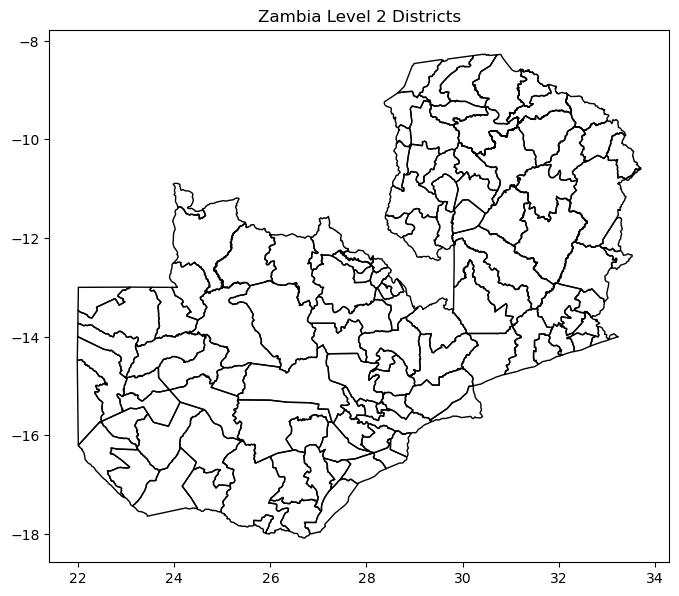

In [8]:
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Load the Zambia districts shapefile directly from your current folder
shapefile_path = 'gadm41_ZMB_2.shp'
zambia_districts = gpd.read_file(shapefile_path)

# 2. Extract the current CRS
current_crs = zambia_districts.crs
print(f"Original Shapefile CRS: {current_crs}")

# 3. Verify and convert ONLY if necessary
if current_crs == "EPSG:4326":
    print("The CRS is already EPSG:4326. No conversion needed!")
else:
    print("CRS does not match EPSG:4326. Converting now...")
    zambia_districts = zambia_districts.to_crs("EPSG:4326")
    print(f"Conversion successful! Updated CRS: {zambia_districts.crs}")

# 4. Plot the shapefile to verify it loaded correctly
zambia_districts.plot(edgecolor='black', facecolor='none', figsize=(8, 8))
plt.title("Zambia Level 2 Districts")
plt.show()

In [9]:
import rioxarray
from shapely.geometry import mapping

# 1. Extract the geometry from the shapefile for our "cookie cutter"
zambia_geometry = zambia_districts.geometry.apply(mapping)
zambia_crs = zambia_districts.crs

# 2. Extract ONLY the main climate variables, and set their spatial properties
# (This leaves 'time_bnds' behind so it doesn't crash the script)
tasmax_da = tasmax_ds['tasmax'].rio.set_spatial_dims(x_dim="lon", y_dim="lat").rio.write_crs("EPSG:4326")
tasmin_da = tasmin_ds['tasmin'].rio.set_spatial_dims(x_dim="lon", y_dim="lat").rio.write_crs("EPSG:4326")
pr_da = pr_ds['pr'].rio.set_spatial_dims(x_dim="lon", y_dim="lat").rio.write_crs("EPSG:4326")

# 3. Apply the spatial mask and crop to the bounding box
print("Clipping tasmax...")
tasmax_zmb = tasmax_da.rio.clip(zambia_geometry, zambia_crs, drop=True)

print("Clipping tasmin...")
tasmin_zmb = tasmin_da.rio.clip(zambia_geometry, zambia_crs, drop=True)

print("Clipping pr...")
pr_zmb = pr_da.rio.clip(zambia_geometry, zambia_crs, drop=True)

# 4. Prove that it worked!
print("\n--- Cropping Verification ---")
print(f"Original tasmax shape (Global): {tasmax_ds['tasmax'].shape}")
print(f"New tasmax shape (Zambia only): {tasmax_zmb.shape}")

Clipping tasmax...
Clipping tasmin...
Clipping pr...

--- Cropping Verification ---
Original tasmax shape (Global): (10957, 10, 10)
New tasmax shape (Zambia only): (10957, 7, 8)


## Task 3: Temporal Aggregation

In [10]:
print("Aggregating daily temperatures to annual means...")

# 1. Aggregate tasmax and tasmin into annual means
# (Using 'YE' instead of 'Y' to clear the warning)
tasmax_annual = tasmax_zmb.resample(time='YE').mean()
tasmin_annual = tasmin_zmb.resample(time='YE').mean()

# 2. Print the first 5 years for a pixel roughly in the middle of Zambia
# (Since tasmax_annual is ALREADY the data, we drop the brackets!)
print("\n--- First 5 Years: Annual Mean Maximum Temperature (°C) ---")
print(tasmax_annual.isel(time=slice(0, 5), lat=3, lon=3).values)

print("\n--- First 5 Years: Annual Mean Minimum Temperature (°C) ---")
print(tasmin_annual.isel(time=slice(0, 5), lat=3, lon=3).values)

Aggregating daily temperatures to annual means...

--- First 5 Years: Annual Mean Maximum Temperature (°C) ---
[28.701145 29.66884  29.341545 29.882734 29.480833]

--- First 5 Years: Annual Mean Minimum Temperature (°C) ---
[16.423235 16.620464 16.657827 16.692686 16.509918]


In [11]:
# 1. Aggregate daily precipitation to annual totals
pr_annual = pr_zmb.resample(time='YE').sum()

# 2. Inspect the first 5 years of total annual rainfall (in mm)
print("--- First 5 Years: Total Annual Precipitation (mm) ---")
print(pr_annual.isel(time=slice(0, 5), lat=3, lon=3).values)

--- First 5 Years: Total Annual Precipitation (mm) ---
[2015.80943988 1710.01023601 2103.32870615 2111.95446278 2214.76725477]


In [12]:
import numpy as np

# 1. FIRST, calculate the valid days and apply the filter 
valid_days_per_year = tasmax_zmb.resample(time='YE').count()

tasmax_annual_filtered = tasmax_annual.where(valid_days_per_year >= 300)
tasmin_annual_filtered = tasmin_annual.where(valid_days_per_year >= 300)
pr_annual_filtered = pr_annual.where(valid_days_per_year >= 300)

print("Task 3 Filter Applied!")

# 2. THEN, run the verification check
min_days = int(valid_days_per_year.min().values)
max_days = int(valid_days_per_year.max().values)

print(f"\nMinimum days found in any year: {min_days}")
print(f"Maximum days found in any year: {max_days}")

# Count how many year-cells had fewer than 300 observations
dropped_count = int((valid_days_per_year < 300).sum().values)
print(f"Number of year-cells with < 300 valid observations: {dropped_count}")

# Check if any values turned to NaN after applying the filter
nans_before = int(np.isnan(tasmax_annual.values).sum())
nans_after = int(np.isnan(tasmax_annual_filtered.values).sum())

print(f"\nTotal NaN values before filter: {nans_before}")
print(f"Total NaN values after filter:  {nans_after}")

if dropped_count == 0:
    print("\nResult: All 30 years have full temporal coverage (>= 300 days), so 0 valid years were dropped.")
else:
    print(f"\nResult: Filter dropped {dropped_count} year-cells due to insufficient data.")

Task 3 Filter Applied!

Minimum days found in any year: 0
Maximum days found in any year: 366
Number of year-cells with < 300 valid observations: 720

Total NaN values before filter: 720
Total NaN values after filter:  720

Result: Filter dropped 720 year-cells due to insufficient data.


## Task 4: Trend and Significance Detection


In [13]:
import numpy as np
import pymannkendall as mk
import xarray as xr

print("Scanning the map: Calculating Sen's Slope for tasmax...")

# 1. Get the latitude and longitude coordinates
lats = tasmax_annual_filtered.lat
lons = tasmax_annual_filtered.lon

# 2. Create a blank "canvas" to store our new trend data
# We fill it with NaNs so the area outside Zambia stays blank
slope_canvas = np.full((len(lats), len(lons)), np.nan)

# 3. Loop through every row (latitude) and column (longitude)
for i in range(len(lats)):
    for j in range(len(lons)):
        
        # Grab the 30-year time series for this exact pixel
        time_series = tasmax_annual_filtered.isel(lat=i, lon=j).values
        
        # Check if it is a valid grid cell (inside Zambia, not completely NaN)
        if not np.isnan(time_series).all():
            
            # Calculate Sen's Slope
            slope_result = mk.sens_slope(time_series)
            
            # The tool gives us the trend per year. 
            # We multiply by 10 to get the robust magnitude of trend PER DECADE!
            slope_per_decade = slope_result.slope * 10
            
            # Save the decadal slope to our canvas at the exact same coordinates
            slope_canvas[i, j] = slope_per_decade

# 4. Turn the raw canvas back into an Xarray map so it keeps its GPS coordinates
tasmax_trend_map = xr.DataArray(slope_canvas, coords=[lats, lons], dims=["lat", "lon"])

print("Calculation Complete!")
print("\n--- Tasmax Decadal Trend Map (°C per decade) ---")
print(tasmax_trend_map.values)

Scanning the map: Calculating Sen's Slope for tasmax...
Calculation Complete!

--- Tasmax Decadal Trend Map (°C per decade) ---
[[       nan 0.41444778 0.59733341 0.51911531        nan        nan
         nan        nan]
 [0.14037206 0.21298218 0.45087179 0.52853792 0.6509304         nan
         nan        nan]
 [0.10252776 0.13314724 0.24008615 0.37866865 0.4971894  0.69070515
  0.85775375        nan]
 [0.1662763  0.15464995 0.20851771 0.33293991 0.47206497 0.7093668
  0.82486813 0.82674874]
 [       nan        nan 0.24777306        nan        nan 0.59963544
  0.63942501 0.619929  ]
 [       nan        nan        nan        nan        nan 0.49779619
  0.503304   0.49555182]
 [       nan        nan        nan        nan        nan 0.36464237
  0.4306177         nan]]


In [14]:
print("Scanning the map: Calculating p-values for tasmax...")

# 1. Create another blank canvas for the p-values
pvalue_canvas = np.full((len(lats), len(lons)), np.nan)

# 2. Loop through the map exactly like before
for i in range(len(lats)):
    for j in range(len(lons)):
        
        time_series = tasmax_annual_filtered.isel(lat=i, lon=j).values
        
        # If it is real land inside Zambia...
        if not np.isnan(time_series).all():
            
            # Run the original Mann-Kendall test!
            mk_result = mk.original_test(time_series)
            
            # Save the p-value to our new canvas
            pvalue_canvas[i, j] = mk_result.p

# 3. Turn the canvas into an Xarray map so it keeps its GPS coordinates
tasmax_pval_map = xr.DataArray(pvalue_canvas, coords=[lats, lons], dims=["lat", "lon"])

print("Calculation Complete!")
print("\n--- Tasmax p-value Map ---")
print(tasmax_pval_map.values)

Scanning the map: Calculating p-values for tasmax...
Calculation Complete!

--- Tasmax p-value Map ---
[[       nan 0.1989481  0.08039115 0.13396534        nan        nan
         nan        nan]
 [0.7212261  0.52069327 0.12494882 0.07440691 0.03527028        nan
         nan        nan]
 [0.59249018 0.54411968 0.14347708 0.03527028 0.01681637 0.01525028
  0.01525028        nan]
 [0.30077176 0.39179344 0.22505715 0.04569547 0.01129535 0.00919304
  0.00343429 0.00384939]
 [       nan        nan 0.06879173        nan        nan 0.00272389
  0.01129535 0.03527028]
 [       nan        nan        nan        nan        nan 0.00481911
  0.02239199 0.08676057]
 [       nan        nan        nan        nan        nan 0.00919304
  0.02950999        nan]]


In [15]:
print("Classifying grid cells based on alpha = 0.05...")

# Create a boolean (True/False) mask where p < 0.05
tasmax_sig_mask = tasmax_pval_map < 0.05

print("Classification Complete!")
print("\n--- Tasmax Significance Mask ---")
print(tasmax_sig_mask.values)

Classifying grid cells based on alpha = 0.05...
Classification Complete!

--- Tasmax Significance Mask ---
[[False False False False False False False False]
 [False False False False  True False False False]
 [False False False  True  True  True  True False]
 [False False False  True  True  True  True  True]
 [False False False False False  True  True  True]
 [False False False False False  True  True False]
 [False False False False False  True  True False]]


In [18]:
import plotly.express as px
import pandas as pd

print("Upgrading map for data storytelling...")

# 1. Prepare the data
df_trend = tasmax_trend_map.to_dataframe(name='Trend')
df_sig = tasmax_sig_mask.to_dataframe(name='Significant')
df = pd.concat([df_trend, df_sig], axis=1).reset_index()
df = df.dropna(subset=['Trend'])

# 2. THE STORYTELLING UPGRADE
def create_story(row):
    trend = row['Trend']
    if row['Significant']:
        sig_text = "✅ Yes (Statistically Proven)"
    else:
        sig_text = "❌ No (Too variable to be certain)"
        
    return f"Warming Rate: +{trend:.2f}°C per decade<br>Is this trend reliable? {sig_text}"

df['What does this mean?'] = df.apply(create_story, axis=1)

# 3. Build the map with human-centered labels
fig = px.scatter_map(
    df,
    lat="lat",
    lon="lon",
    color="Trend",
    color_continuous_scale="RdBu_r", 
    color_continuous_midpoint=0,     
    hover_name="What does this mean?", 
    hover_data={
        "lat": False, 
        "lon": False, 
        "Trend": False,       
        "Significant": False, 
        "What does this mean?": False 
    },
    title="<b>Zambia is Getting Hotter</b><br><sup>Decadal rise in maximum temperatures (1981-2010)</sup>",
    labels={"Trend": "Warming (°C / Decade)"}, 
    map_style="carto-darkmatter",
    zoom=4.5,
    center={"lat": -13.5, "lon": 28.0},
    opacity=0.9
)

# 4. UI Polish: Larger circles (removed the border so it renders safely!)
fig.update_traces(
    marker=dict(size=24),
    hovertemplate="<b>%{hovertext}</b><extra></extra>" 
)

fig.update_layout(
    margin={"r":0,"t":60,"l":0,"b":0},
    title_font_size=20
)

# 5. Show and Export
fig.show()
fig.write_html("zambia_climate_interactive.html")
print("\nSuccess! Refresh your browser tab to see the upgraded map.")

Upgrading map for data storytelling...



Success! Refresh your browser tab to see the upgraded map.


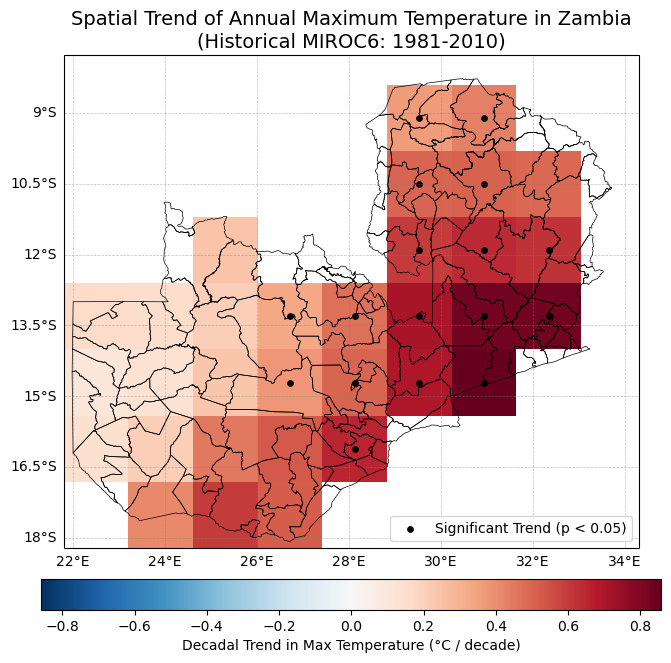

Saved map as 'tasmax_spatial_trend_map.png'


In [19]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

# 1. Set up the figure and the map projection
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})

# 2. Extract Coordinates and Variables
lons = tasmax_trend_map.lon.values
lats = tasmax_trend_map.lat.values
trend_values = tasmax_trend_map.values
sig_values = tasmax_sig_mask.values

# 3. Create a meshgrid for plotting
lon_mesh, lat_mesh = np.meshgrid(
    np.append(lons - 0.5 * np.diff(lons)[0], lons[-1] + 0.5 * np.diff(lons)[0]),
    np.append(lats - 0.5 * np.diff(lats)[0], lats[-1] + 0.5 * np.diff(lats)[0])
)

# 4. Plot the Trend Data (FIXED SYMMETRY)
# We find the absolute maximum trend to make the colorbar perfectly symmetrical around zero
max_trend = np.nanmax(np.abs(trend_values))

trend_plot = ax.pcolormesh(
    lon_mesh, lat_mesh, trend_values, 
    cmap='RdBu_r', 
    vmin=-max_trend, vmax=max_trend, # Symmetrical bounds force 0 to be white!
    transform=ccrs.PlateCarree()
)

# Add a colorbar
cbar = plt.colorbar(trend_plot, ax=ax, orientation='horizontal', pad=0.05, shrink=0.8)
cbar.set_label("Decadal Trend in Max Temperature (°C / decade)")

# 5. Overlay Significance Stippling
sig_lon, sig_lat = np.meshgrid(lons, lats)
sig_lon_flat = sig_lon[sig_values]
sig_lat_flat = sig_lat[sig_values]

ax.scatter(sig_lon_flat, sig_lat_flat, color='black', s=15, marker='o', transform=ccrs.PlateCarree(), label='Significant Trend (p < 0.05)')

# 6. Overlay the District Boundaries
zambia_districts.plot(ax=ax, edgecolor='black', facecolor='none', linewidth=0.5, transform=ccrs.PlateCarree())

# 7. Add Labels and Titles
ax.set_title("Spatial Trend of Annual Maximum Temperature in Zambia\n(Historical MIROC6: 1981-2010)", fontsize=14)

# Draw gridlines with labels
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False

plt.legend(loc='lower right')

# Make sure it always goes BEFORE plt.show()
plt.savefig("tasmax_spatial_trend_map.png", dpi=300, bbox_inches='tight')

plt.show()
print("Saved map as 'tasmax_spatial_trend_map.png'")

In [20]:
import numpy as np

# 1. Filter out the NaN (blank) pixels so we only do math on valid Zambia land
valid_trends = trend_values[~np.isnan(trend_values)]

# 2. Calculate the required statistics for the table
min_trend = np.min(valid_trends)
max_trend = np.max(valid_trends)
mean_trend = np.mean(valid_trends)
median_trend = np.median(valid_trends)

# 3. Calculate the percentage of significant grid cells
total_valid_cells = len(valid_trends)
significant_cells = np.sum(sig_values) # In Python, 'True' counts as 1
percent_significant = (significant_cells / total_valid_cells) * 100

# 4. Print the results perfectly formatted for your report
print("--- Tasmax Trend Summary Statistics (°C/decade) ---")
print(f"Minimum Slope: {min_trend:.3f}")
print(f"Maximum Slope: {max_trend:.3f}")
print(f"Mean Slope:    {mean_trend:.3f}")
print(f"Median Slope:  {median_trend:.3f}")
print(f"Significant Grid Cells: {percent_significant:.1f}%")

--- Tasmax Trend Summary Statistics (°C/decade) ---
Minimum Slope: 0.103
Maximum Slope: 0.858
Mean Slope:    0.453
Median Slope:  0.484
Significant Grid Cells: 53.1%


## Calculate Trends for Minimum Temperature for TASMIN

In [21]:
import numpy as np
import pymannkendall as mk
import xarray as xr

print("Task 4: Calculating Sen's Slope and p-values for TASMIN...")

# Get coordinates from the tasmin filtered dataset
lats = tasmin_annual_filtered.lat
lons = tasmin_annual_filtered.lon

# Create blank canvases
slope_canvas = np.full((len(lats), len(lons)), np.nan)
pvalue_canvas = np.full((len(lats), len(lons)), np.nan)

# Loop through every grid cell
for i in range(len(lats)):
    for j in range(len(lons)):
        time_series = tasmin_annual_filtered.isel(lat=i, lon=j).values
        
        if not np.isnan(time_series).all():
            mk_result = mk.original_test(time_series)
            
            # Save slope (multiplied by 10 for per decade) and p-value
            slope_canvas[i, j] = mk_result.slope * 10
            pvalue_canvas[i, j] = mk_result.p

# Turn canvases into xarray maps
tasmin_trend_map = xr.DataArray(slope_canvas, coords=[lats, lons], dims=["lat", "lon"])
tasmin_pval_map = xr.DataArray(pvalue_canvas, coords=[lats, lons], dims=["lat", "lon"])

# Create the significance mask (p < 0.05)
tasmin_sig_mask = tasmin_pval_map < 0.05

import numpy as np

print("--- RESULTS FOR DELIVERABLE 3 (MINIMUM TEMPERATURE) ---")

# Extract the raw numbers from our tasmin maps
tasmin_slopes = tasmin_trend_map.values
tasmin_pvals = tasmin_pval_map.values

# Filter out the NaNs (the empty borders) so we only calculate stats on valid land pixels
valid_tasmin_slopes = tasmin_slopes[~np.isnan(tasmin_slopes)]
valid_tasmin_pvals = tasmin_pvals[~np.isnan(tasmin_pvals)]

# Calculate the statistics
min_slope = np.min(valid_tasmin_slopes)
max_slope = np.max(valid_tasmin_slopes)
mean_slope = np.mean(valid_tasmin_slopes)
median_slope = np.median(valid_tasmin_slopes)
sig_percent = (np.sum(valid_tasmin_pvals < 0.05) / len(valid_tasmin_pvals)) * 100

# Print them out neatly for your report
print(f"Minimum Slope:  {min_slope:.4f} °C per decade")
print(f"Maximum Slope:  {max_slope:.4f} °C per decade")
print(f"Mean Slope:     {mean_slope:.4f} °C per decade")
print(f"Median Slope:   {median_slope:.4f} °C per decade")
print(f"Significant Cells (p < 0.05): {sig_percent:.1f}%")

Task 4: Calculating Sen's Slope and p-values for TASMIN...
--- RESULTS FOR DELIVERABLE 3 (MINIMUM TEMPERATURE) ---
Minimum Slope:  0.1868 °C per decade
Maximum Slope:  0.4419 °C per decade
Mean Slope:     0.2995 °C per decade
Median Slope:   0.2924 °C per decade
Significant Cells (p < 0.05): 96.9%


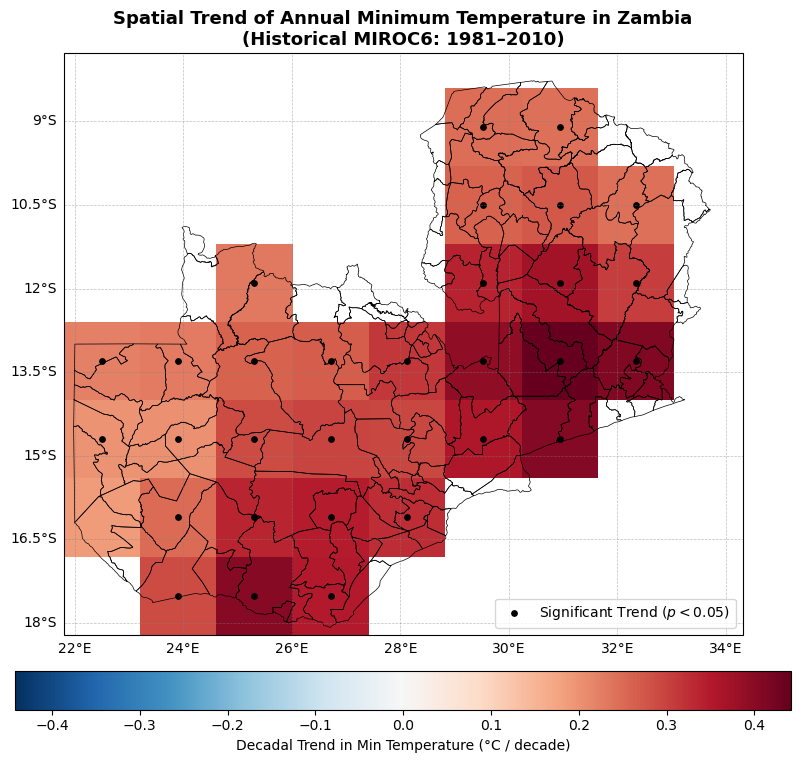

Saved map as 'tasmin_spatial_trend_map.png'


In [22]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

# 1. Set up the figure and map projection
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})

# 2. Extract Coordinates and Variables for tasmin
lons = tasmin_trend_map.lon.values
lats = tasmin_trend_map.lat.values
trend_values = tasmin_trend_map.values
sig_values = tasmin_sig_mask.values

# 3. Create cell-centered grid bounds for pcolormesh
lon_step = np.diff(lons)[0]
lat_step = np.diff(lats)[0]

lon_mesh, lat_mesh = np.meshgrid(
    np.append(lons - 0.5 * lon_step, lons[-1] + 0.5 * lon_step),
    np.append(lats - 0.5 * lat_step, lats[-1] + 0.5 * lat_step)
)

# 4. Symmetrical color bounds (forces 0 to map to neutral white)
max_trend = np.nanmax(np.abs(trend_values))

trend_plot = ax.pcolormesh(
    lon_mesh, lat_mesh, trend_values, 
    cmap='RdBu_r', 
    vmin=-max_trend, vmax=max_trend,
    transform=ccrs.PlateCarree()
)

# Horizontal colorbar
cbar = plt.colorbar(trend_plot, ax=ax, orientation='horizontal', pad=0.05, shrink=0.8)
cbar.set_label("Decadal Trend in Min Temperature (°C / decade)")

# 5. Overlay Significance Stippling (p < 0.05)
sig_lon, sig_lat = np.meshgrid(lons, lats)
sig_lon_flat = sig_lon[sig_values]
sig_lat_flat = sig_lat[sig_values]

ax.scatter(
    sig_lon_flat, sig_lat_flat, 
    color='black', s=15, marker='o', 
    transform=ccrs.PlateCarree(), 
    label='Significant Trend ($p < 0.05$)'
)

# 6. Overlay Administrative District Boundaries
zambia_districts.plot(
    ax=ax, edgecolor='black', facecolor='none', 
    linewidth=0.5, transform=ccrs.PlateCarree()
)

# 7. Labels, Gridlines, and Title
ax.set_title("Spatial Trend of Annual Minimum Temperature in Zambia\n(Historical MIROC6: 1981–2010)", fontsize=13, fontweight='bold')

gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False

plt.legend(loc='lower right')
plt.tight_layout()

# Save image for report
plt.savefig("tasmin_spatial_trend_map.png", dpi=300, bbox_inches='tight')
plt.show()
print("Saved map as 'tasmin_spatial_trend_map.png'")

## Trend, Significance & Verification for pr

In [23]:
import numpy as np
import pymannkendall as mk
import xarray as xr

print("Task 4: Calculating Sen's Slope and p-values for PRECIPITATION (pr)...")

# Extract coordinates from the filtered pr dataset
lats = pr_annual_filtered.lat
lons = pr_annual_filtered.lon

# Initialize empty canvases
slope_canvas = np.full((len(lats), len(lons)), np.nan)
pvalue_canvas = np.full((len(lats), len(lons)), np.nan)

# Iterate across latitude and longitude
for i in range(len(lats)):
    for j in range(len(lons)):
        time_series = pr_annual_filtered.isel(lat=i, lon=j).values
        
        # Check if the pixel contains valid data
        if not np.isnan(time_series).all():
            mk_result = mk.original_test(time_series)
            
            # Save slope per decade (* 10) and p-value
            slope_canvas[i, j] = mk_result.slope * 10
            pvalue_canvas[i, j] = mk_result.p

# Package back into Xarray DataArrays
pr_trend_map = xr.DataArray(slope_canvas, coords=[lats, lons], dims=["lat", "lon"])
pr_pval_map = xr.DataArray(pvalue_canvas, coords=[lats, lons], dims=["lat", "lon"])
pr_sig_mask = pr_pval_map < 0.05

print("Calculations Complete!\n")

# --- VERIFICATION OUTPUTS (For your Report Table!) ---
print("--- RESULTS FOR DELIVERABLE 3 (PRECIPITATION) ---")
valid_slopes = slope_canvas[~np.isnan(slope_canvas)]
valid_pvals = pvalue_canvas[~np.isnan(pvalue_canvas)]

min_slope = np.min(valid_slopes)
max_slope = np.max(valid_slopes)
mean_slope = np.mean(valid_slopes)
median_slope = np.median(valid_slopes)
sig_percent = (np.sum(valid_pvals < 0.05) / len(valid_pvals)) * 100

print(f"Minimum Slope:  {min_slope:.4f} mm/day per decade")
print(f"Maximum Slope:  {max_slope:.4f} mm/day per decade")
print(f"Mean Slope:     {mean_slope:.4f} mm/day per decade")
print(f"Median Slope:   {median_slope:.4f} mm/day per decade")
print(f"Significant Cells (p < 0.05): {sig_percent:.1f}%")

Task 4: Calculating Sen's Slope and p-values for PRECIPITATION (pr)...
Calculations Complete!

--- RESULTS FOR DELIVERABLE 3 (PRECIPITATION) ---
Minimum Slope:  -89.4257 mm/day per decade
Maximum Slope:  67.7364 mm/day per decade
Mean Slope:     -16.7990 mm/day per decade
Median Slope:   -28.1332 mm/day per decade
Significant Cells (p < 0.05): 3.1%


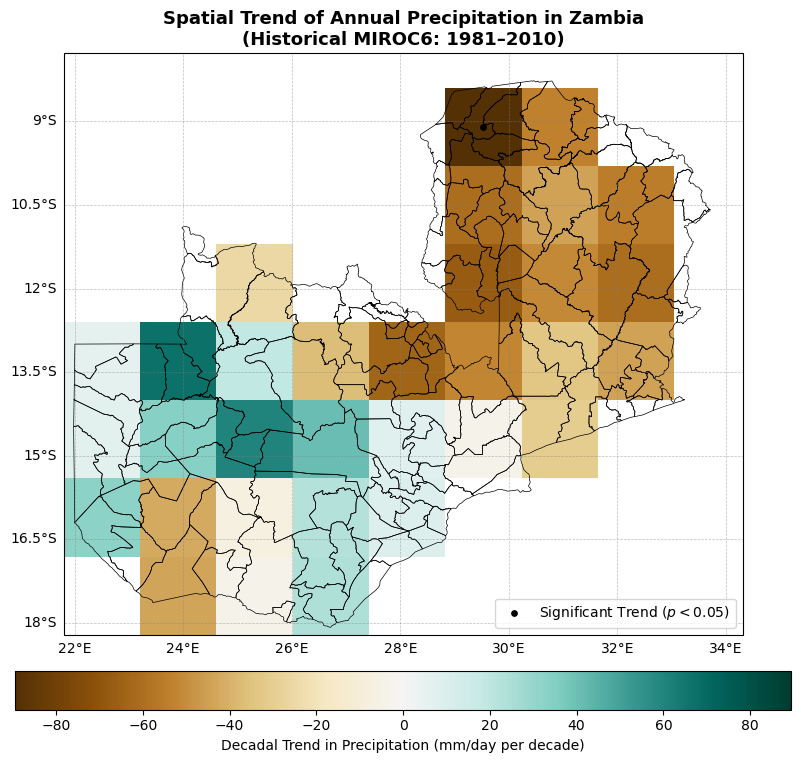

Saved map as 'pr_spatial_trend_map.png'


In [24]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

# 1. Set up the figure and map projection
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})

# 2. Extract Coordinates and Variables for pr
lons = pr_trend_map.lon.values
lats = pr_trend_map.lat.values
trend_values = pr_trend_map.values
sig_values = pr_sig_mask.values

# 3. Create cell-centered grid bounds for pcolormesh
lon_step = np.diff(lons)[0]
lat_step = np.diff(lats)[0]
lon_mesh, lat_mesh = np.meshgrid(
    np.append(lons - 0.5 * lon_step, lons[-1] + 0.5 * lon_step),
    np.append(lats - 0.5 * lat_step, lats[-1] + 0.5 * lat_step)
)

# 4. Plot the Trend Data using BrBG (Brown to Green)
max_trend = np.nanmax(np.abs(trend_values))

trend_plot = ax.pcolormesh(
    lon_mesh, lat_mesh, trend_values, 
    cmap='BrBG', 
    vmin=-max_trend, vmax=max_trend,
    transform=ccrs.PlateCarree()
)

# Horizontal colorbar
cbar = plt.colorbar(trend_plot, ax=ax, orientation='horizontal', pad=0.05, shrink=0.8)
cbar.set_label("Decadal Trend in Precipitation (mm/day per decade)")

# 5. Overlay Significance Stippling (p < 0.05)
sig_lon, sig_lat = np.meshgrid(lons, lats)
sig_lon_flat = sig_lon[sig_values]
sig_lat_flat = sig_lat[sig_values]

# Only plot legend/dots if there are actually significant cells found
if len(sig_lon_flat) > 0:
    ax.scatter(
        sig_lon_flat, sig_lat_flat, 
        color='black', s=15, marker='o', 
        transform=ccrs.PlateCarree(), 
        label='Significant Trend ($p < 0.05$)'
    )
    plt.legend(loc='lower right')

# 6. Overlay Administrative District Boundaries
zambia_districts.plot(
    ax=ax, edgecolor='black', facecolor='none', 
    linewidth=0.5, transform=ccrs.PlateCarree()
)

# 7. Labels, Gridlines, and Title
ax.set_title("Spatial Trend of Annual Precipitation in Zambia\n(Historical MIROC6: 1981–2010)", fontsize=13, fontweight='bold')

gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False

plt.tight_layout()
plt.savefig("pr_spatial_trend_map.png", dpi=300, bbox_inches='tight')
plt.show()
print("Saved map as 'pr_spatial_trend_map.png'")